นาย อัญญาฤทธิ์ จ๊ะราจา 670510777 โฟล์ค 0824777935

# Mask R-CNN (torchvision)

ถอดจากภาพตัวอย่าง โดยคงลำดับเซลล์ การกรอง confidence > 0.5 และการแสดง masks / boxes

เปิดใน Google Colab แล้วรันจากบนลงล่าง ใช้รูปจาก URL ตามตัวอย่างได้ทันที หากใช้รูปใน Drive ให้แก้ `folder_path` และ `IMG_PATH` ให้ตรงกับไฟล์จริง (ชื่อโฟลเดอร์และไฟล์ในภาพถูกปิดไว้)

เปลี่ยน `pretrained=True` เป็น `weights=models.detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT` ตาม [เอกสาร torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.maskrcnn_resnet50_fpn.html) โดยใช้ weights COCO_V1 เดิม การรันครั้งแรกจะดาวน์โหลด weights ของโมเดล


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
folder_path = '/content/drive/MyDrive/Colab Notebooks/ImgProc/Images/' # Set your image folder here.

In [ ]:
%pip -q install torch torchvision pillow matplotlib numpy requests

In [ ]:
import torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as T
from torchvision import models
import requests, io, os

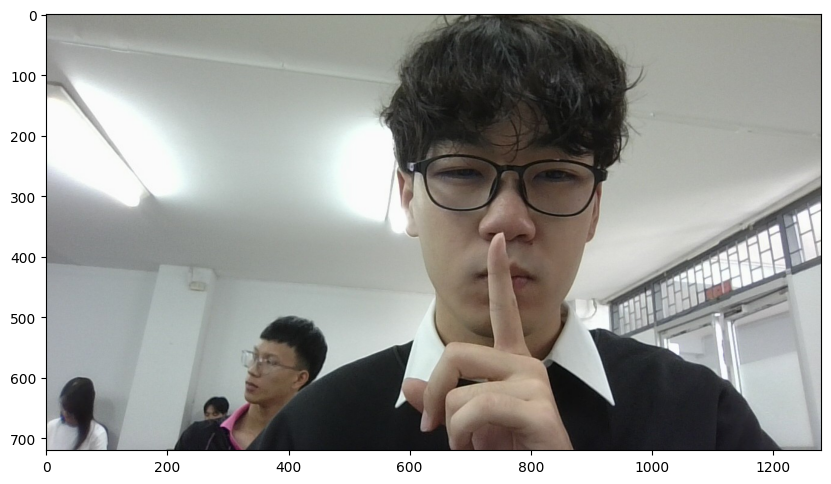

In [ ]:
IMG_PATH = "sui.jpg"

img_pil = Image.open(os.path.join(folder_path, IMG_PATH))
plt.figure(figsize=(10,10))
plt.imshow(img_pil)
plt.show()

In [ ]:
# Mask R-CNN expects 0..1 tensors without normalization
to_tensor = T.ToTensor()
img_tensor = to_tensor(img_pil)

In [ ]:
model = models.detection.maskrcnn_resnet50_fpn(
    weights=models.detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT
).eval()

In [ ]:
with torch.no_grad():
    outputs = model([img_tensor])[0]

In [ ]:
# Parse outputs
scores = outputs["scores"].cpu().numpy()
keep = scores > 0.5 # confidence threshold
boxes = outputs["boxes"][keep].cpu().numpy().astype(int)
masks = (outputs["masks"][keep] > 0.5).squeeze(1).cpu().numpy() # [N,H,W]
labels = outputs["labels"][keep].cpu().numpy()

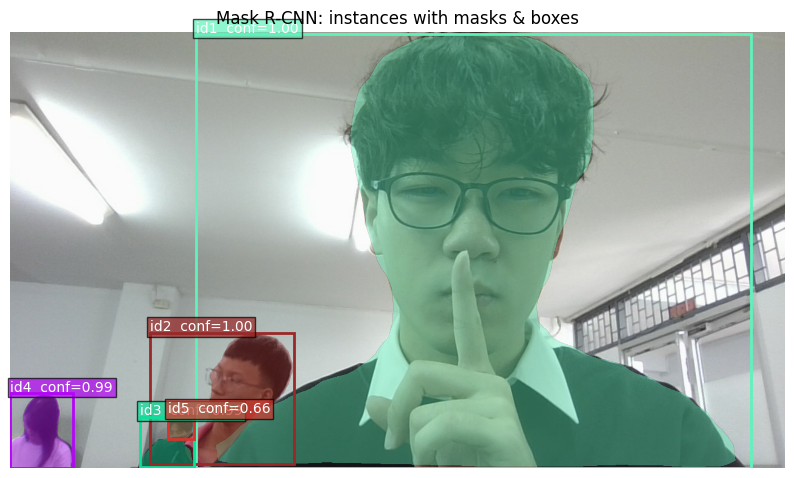

In [ ]:
# Visualize
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(img_pil); ax.axis("off")
np.random.seed(42)
for i, (box, mask, lab, sc) in enumerate(zip(boxes, masks, labels,
                                          scores[keep])):
    y1, x1, y2, x2 = box[1], box[0], box[3], box[2]
    color = np.random.rand(3,)
    # draw mask
    h, w = mask.shape
    colored = np.zeros((h, w, 4), dtype=np.float32)
    colored[mask] = [*color, 0.4] # RGBA with alpha
    ax.imshow(colored)
    # draw bbox
    rect = plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False,
                         linewidth=2, edgecolor=color)
    ax.add_patch(rect)
    ax.text(x1, y1-3, f"id{i+1}  conf={sc:.2f}", color='white',
            bbox=dict(facecolor=tuple(color), alpha=0.7, pad=2))

plt.title("Mask R-CNN: instances with masks & boxes")
plt.show()